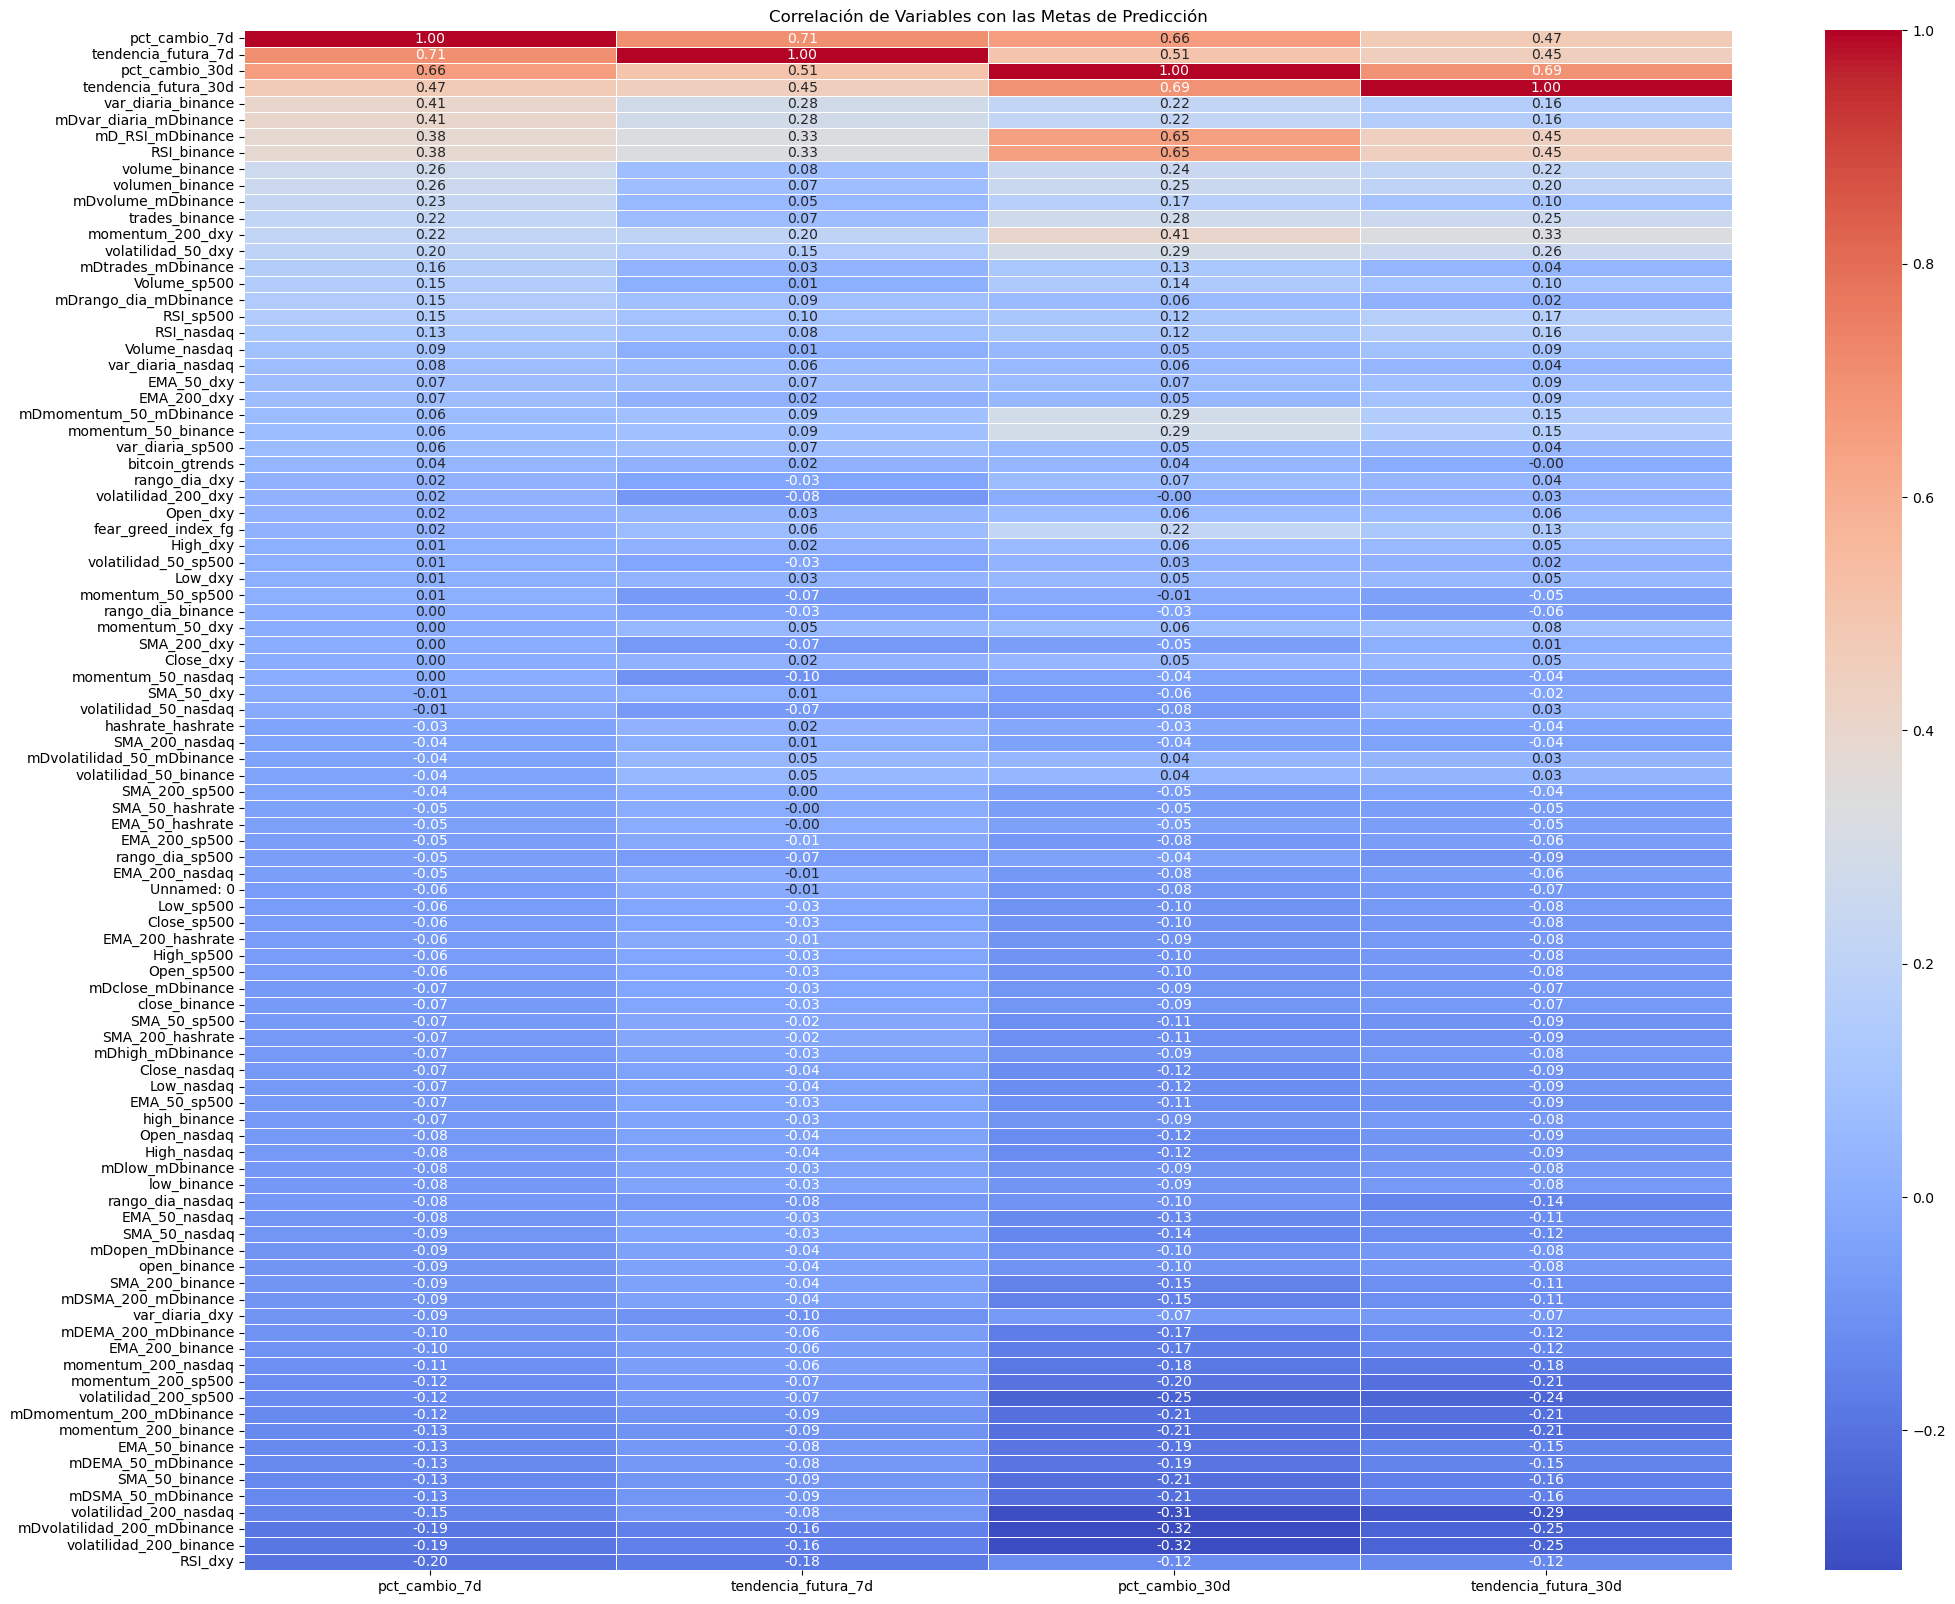

In [45]:
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("C:\\Users\\vegag\\OneDrive\\datos\\segundo\\2ndo cuatri\\PD1\\cleaned_data.csv")

# Calcular la correlación con las variables objetivo
corr_target = df.corr()[['pct_cambio_7d', 'tendencia_futura_7d', 'pct_cambio_30d', 'tendencia_futura_30d']].sort_values(by='pct_cambio_7d', ascending=False)

# Mostrar las variables más correlacionadas con las metas
plt.figure(figsize=(24, 20))
sns.heatmap(corr_target, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlación de Variables con las Metas de Predicción")
plt.show()


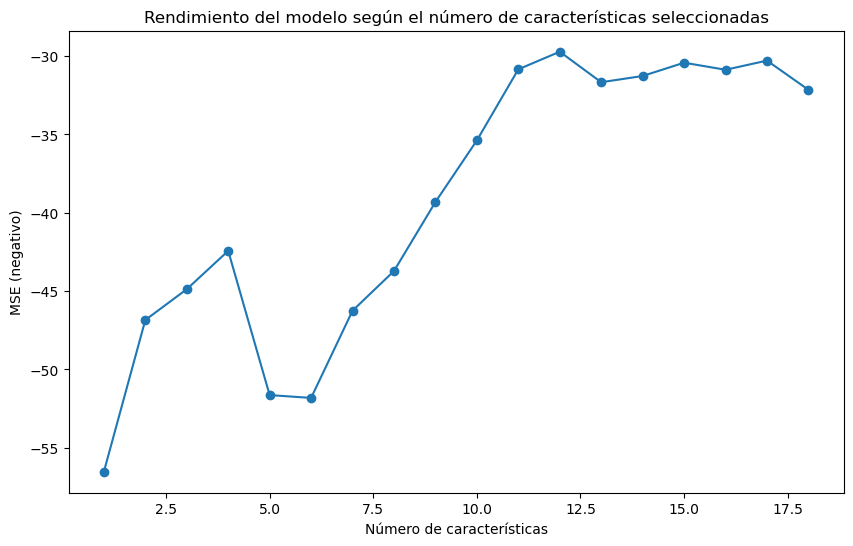

Número óptimo de características seleccionadas: 12


In [62]:
# Lo que haremos será calcular el número óptimo de características que debemos utilizar para predecir 
# la variable objetivo 'pct_cambio_7d'. Para esto, probaremos con diferentes cantidades de características 
# (desde 1 hasta todas) y evaluaremos el rendimiento de un modelo de regresión (RandomForestRegressor) 
# usando validación cruzada. Finalmente, seleccionaremos el número de características que minimice el 
# error cuadrático medio negativo (MSE), lo cual nos indicará el mejor conjunto de características para 
# hacer nuestras predicciones de manera más precisa y eficiente.

from sklearn.model_selection import cross_val_score
from sklearn.feature_selection import SelectKBest, mutual_info_regression
from sklearn.ensemble import RandomForestRegressor
import numpy as np
import matplotlib.pyplot as plt

# 🔹 Definir la variable objetivo
target_7d = "pct_cambio_7d"

# 🔹 Definir las variables explicativas
features = [
    'Open_dxy', 'mDSMA_50_mDbinance', 'EMA_50_dxy', 'momentum_200_binance', 
    'momentum_200_sp500', 'momentum_200_dxy', 'volatilidad_200_binance', 
    'volatilidad_200_nasdaq', 'volatilidad_50_dxy', 'RSI_binance', 'RSI_sp500', 
    'RSI_dxy', 'var_diaria_binance', 'mDrango_dia_mDbinance', 'volumen_binance', 
    'trades_binance', 'fear_greed_index_fg', 'bitcoin_gtrends'
]

# 🔹 Definir las características (X) y el target (y)
X_7d = df[features]  # Asegúrate de que 'features' es la lista correcta de características
Y_7d = df[target_7d]  # Asegúrate de que 'target_7d' es la columna correcta

# Lista para almacenar el rendimiento con k características
scores_7d = []

# Probar diferentes valores de k (número de características seleccionadas)
for k in range(1, len(features) + 1):  # Seleccionamos k características desde 1 hasta el total
    # Selección de características con SelectKBest
    selector = SelectKBest(mutual_info_regression, k=k)
    X_selected_7d = selector.fit_transform(X_7d, Y_7d)
    
    # Validación cruzada con el modelo (RandomForestRegressor en este caso)
    rf = RandomForestRegressor()
    score = cross_val_score(rf, X_selected_7d, Y_7d, cv=5, scoring='neg_mean_squared_error').mean()  # Promedio de MSE negativo
    scores_7d.append(score)

# Graficar el rendimiento del modelo en función del número de características seleccionadas
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(features) + 1), scores_7d, marker='o')
plt.title('Rendimiento del modelo según el número de características seleccionadas')
plt.xlabel('Número de características')
plt.ylabel('MSE (negativo)')
plt.show()

# Encontrar el número óptimo de características (k) basado en el mejor rendimiento
best_k_7d = np.argmax(scores_7d) + 1  # +1 ya que el rango empieza en 1
print(f'Número óptimo de características seleccionadas: {best_k_7d}')

                 Feature_7d  Importance_7d
9               RSI_binance       0.353496
7    volatilidad_200_nasdaq       0.141615
5          momentum_200_dxy       0.131236
2                EMA_50_dxy       0.084453
1        mDSMA_50_mDbinance       0.078164
6   volatilidad_200_binance       0.052549
3      momentum_200_binance       0.042734
8        volatilidad_50_dxy       0.041195
11                  RSI_dxy       0.019470
10                RSI_sp500       0.018887
4        momentum_200_sp500       0.013960
0                  Open_dxy       0.009985
16      fear_greed_index_fg       0.004765
15           trades_binance       0.003382
14          volumen_binance       0.001785
12       var_diaria_binance       0.001183
13    mDrango_dia_mDbinance       0.000972
17          bitcoin_gtrends       0.000170


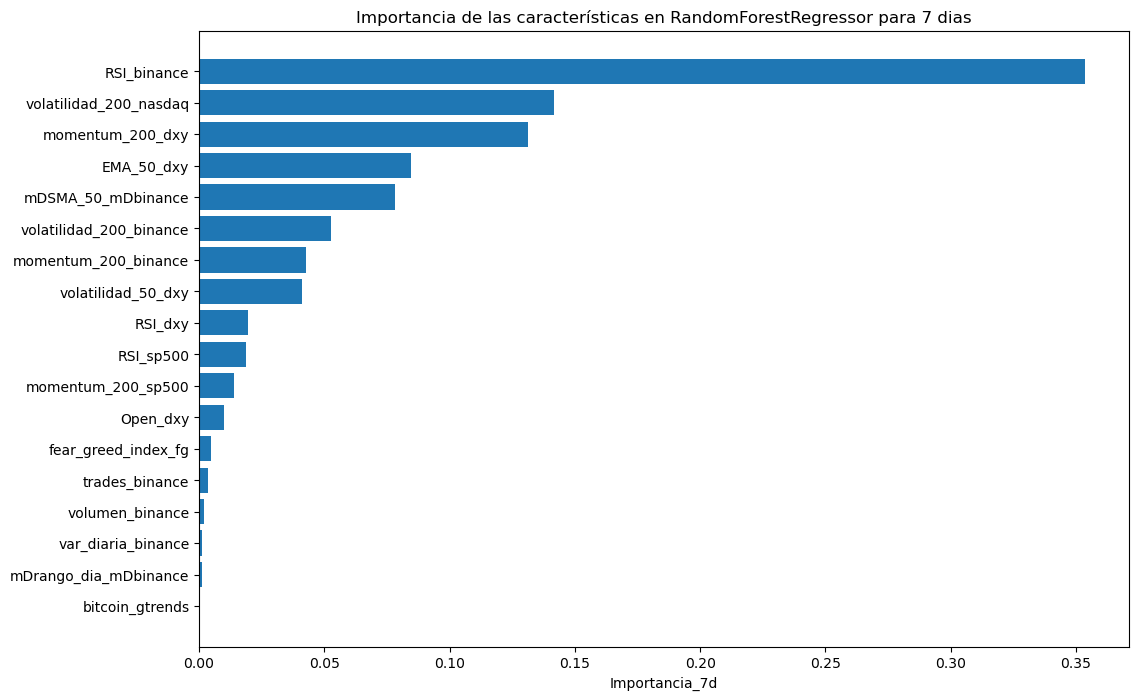

['RSI_binance' 'volatilidad_200_nasdaq' 'momentum_200_dxy' 'EMA_50_dxy'
 'mDSMA_50_mDbinance' 'volatilidad_200_binance' 'momentum_200_binance'
 'volatilidad_50_dxy' 'RSI_dxy' 'RSI_sp500' 'momentum_200_sp500'
 'Open_dxy']


In [55]:
# Lo que haremos en este código es entrenar un modelo de regresión RandomForestRegressor para predecir el cambio porcentual 
# de 7 días ('pct_cambio_7d').Posteriormente, evaluaremos la importancia de las características explicativas
# (como 'Open_dxy', 'RSI_binance', etc.) utilizando el atributo 'feature_importances_'  del modelo entrenado. Al final, 
# ordenaremos y graficaremos estas importancias para identificar cuáles son las características más relevantes 
# para la predicción y seleccionaremos las 12 más importantes (este número por los resultados obtenidos en la celda anterior)

from sklearn.ensemble import RandomForestRegressor
import pandas as pd
import matplotlib.pyplot as plt

# 🔹 Definir la variable objetivo y las características explicativas
target_7d = "pct_cambio_7d"
features = [
    'Open_dxy', 'mDSMA_50_mDbinance', 'EMA_50_dxy', 'momentum_200_binance', 
    'momentum_200_sp500', 'momentum_200_dxy', 'volatilidad_200_binance', 
    'volatilidad_200_nasdaq', 'volatilidad_50_dxy', 'RSI_binance', 'RSI_sp500', 
    'RSI_dxy', 'var_diaria_binance', 'mDrango_dia_mDbinance', 'volumen_binance', 
    'trades_binance', 'fear_greed_index_fg', 'bitcoin_gtrends'
]

# 🔹 Definir las características (X) y el target (y)
X_7d = df[features]  # Asegúrate de que 'features' es la lista correcta de características
y_7d = df[target_7d]  # Asegúrate de que 'target_7d' es la columna correcta

soluciones = df[["pct_cambio_7d" , "tendencia_futura_7d"]]

# 🔹 Entrenar el modelo RandomForestRegressor
rf_7d = RandomForestRegressor(n_estimators=100, random_state=42)
rf_7d.fit(X, y)

# 🔹 Obtener la importancia de las características
importances_7d = rf_7d.feature_importances_

# 🔹 Crear un DataFrame para las características y sus importancias
feature_importances_7d = pd.DataFrame({
    'Feature_7d': features,
    'Importance_7d': importances_7d
})

# 🔹 Ordenar las características por importancia
feature_importances_7d = feature_importances_7d.sort_values(by='Importance_7d', ascending=False)

# Mostrar las características más importantes
print(feature_importances_7d)

# 🔹 Graficar la importancia de las características
plt.figure(figsize=(12, 8))
plt.barh(feature_importances_7d['Feature_7d'], feature_importances_7d['Importance_7d'])
plt.xlabel('Importancia_7d')
plt.title('Importancia de las características en RandomForestRegressor para 7 dias')
plt.gca().invert_yaxis()  # Para mostrar las características más importantes arriba
plt.show()

# Seleccionar las 12 características más importantes
top_features_7d = feature_importances_7d['Feature_7d'].head(12).values

print(top_features_7d)

In [59]:
df_respuesta_7d = df[['RSI_binance', 'volatilidad_200_nasdaq' ,'momentum_200_dxy' ,'EMA_50_dxy',
 'mDSMA_50_mDbinance', 'volatilidad_200_binance' ,'momentum_200_binance',
 'volatilidad_50_dxy', 'RSI_dxy' ,'RSI_sp500' ,'momentum_200_sp500',
 'Open_dxy', 'pct_cambio_7d', 'tendencia_futura_7d']] #añadimos las variables respuesta a las seleccionadas

df_respuesta_7d.to_csv("C:\\Users\\vegag\\OneDrive\\datos\\segundo\\2ndo cuatri\\PD1\\dataset_7d.csv")

Variables seleccionadas tras Mutual Information: ['volatilidad_200_nasdaq', 'EMA_50_dxy', 'mDSMA_50_mDbinance', 'volatilidad_200_binance', 'volatilidad_50_dxy', 'momentum_200_sp500', 'momentum_200_dxy', 'Open_dxy']

Importancia de variables según Random Forest:
                  Variable  Importancia
0   volatilidad_200_nasdaq     0.370519
6         momentum_200_dxy     0.239307
1               EMA_50_dxy     0.099648
2       mDSMA_50_mDbinance     0.090384
3  volatilidad_200_binance     0.080189
4       volatilidad_50_dxy     0.073170
5       momentum_200_sp500     0.025981
7                 Open_dxy     0.020802


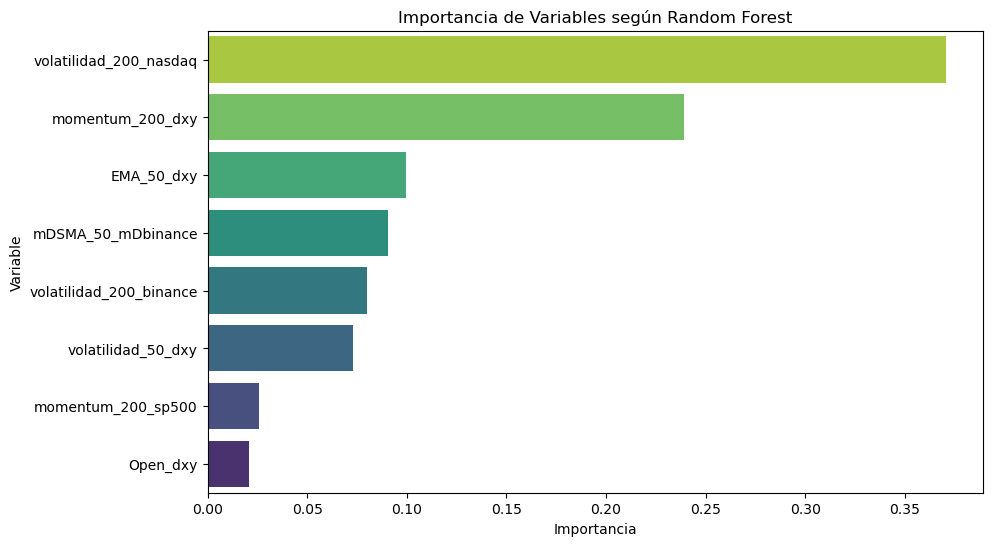

In [61]:
# Lo que haremos en este código es realizar una selección de variables utilizando la información mutua (Mutual Information), 
# para identificar las características más relevantes para predecir el cambio porcentual de 30 días ('pct_cambio_30d').
# Luego, utilizaremos un modelo de RandomForestRegressor para confirmar la importancia de las variables seleccionadas.
# Finalmente, visualizaremos las importancias de las variables seleccionadas a través de un gráfico de barras.

from sklearn.model_selection import cross_val_score
from sklearn.feature_selection import SelectKBest, mutual_info_regression
from sklearn.ensemble import RandomForestRegressor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 🔹 Definir la variable objetivo
target_30d = "pct_cambio_30d"

# 🔹 Definir las variables explicativas
features = [
    'Open_dxy', 'mDSMA_50_mDbinance', 'EMA_50_dxy', 'mDmomentum_50_mDbinance', 
    'momentum_200_sp500', 'momentum_200_dxy', 'volatilidad_200_binance', 
    'volatilidad_200_nasdaq', 'volatilidad_50_dxy', 'RSI_binance', 'RSI_nasdaq',
    'RSI_dxy', 'mDvar_diaria_mDbinance', 'mDrango_dia_mDbinance', 'volumen_binance', 
    'trades_binance', 'fear_greed_index_fg', 'bitcoin_gtrends'
]

# 🔹 Definir las características (X) y el target (y)
X_30d = df[features]
y_30d = df[target_30d]

### 📌 PASO 1: SELECCIÓN INICIAL CON MUTUAL INFORMATION ###
selector = SelectKBest(mutual_info_regression, k="all")  # Evaluamos todas las variables
selector.fit(X_30d, y_30d)
mi_scores = selector.scores_

# Crear DataFrame con los resultados
mi_df = pd.DataFrame({"Variable": features, "MI_Score": mi_scores})
mi_df = mi_df.sort_values(by="MI_Score", ascending=False)

# Filtrar variables con MI > 0.5
selected_features = mi_df[mi_df["MI_Score"] > 0.5]["Variable"].tolist()
print(f"Variables seleccionadas tras Mutual Information: {selected_features}")

### 📌 PASO 2: CONFIRMAR IMPORTANCIA CON RANDOM FOREST ###
rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X_30d[selected_features], y_30d)

# Obtener importancia de variables
importances = rf.feature_importances_
importance_df = pd.DataFrame({"Variable": selected_features, "Importancia": importances})
importance_df = importance_df.sort_values(by="Importancia", ascending=False)

print("\nImportancia de variables según Random Forest:")
print(importance_df)

import seaborn as sns
import matplotlib.pyplot as plt

# Ordenar el DataFrame de importancia
importance_df = importance_df.sort_values(by="Importancia", ascending=True)

# Crear la gráfica de barras
plt.figure(figsize=(10, 6))
sns.barplot(x="Importancia", y="Variable", data=importance_df, palette="viridis")
plt.title("Importancia de Variables según Random Forest")
plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.gca().invert_yaxis()
plt.show()

In [65]:
df_respuesta_30d = df[['volatilidad_200_nasdaq', 'EMA_50_dxy', 'mDSMA_50_mDbinance', 'volatilidad_200_binance', 
                      'volatilidad_50_dxy', 'momentum_200_sp500', 'momentum_200_dxy', 'Open_dxy', 'pct_cambio_30d',
                       'tendencia_futura_30d']]  #añadimos las variables respuesta a las seleccionadas

df_respuesta_30d.to_csv("C:\\Users\\vegag\\OneDrive\\datos\\segundo\\2ndo cuatri\\PD1\\dataset_30d.csv")